# Predicting used-car prices in Sri Lanka with NGBoost (Natural Gradient Boosting)

**Problem:** buyers and sellers in Sri Lanka have no reliable way to judge a fair price for a used car.
Vehicle imports were suspended from 2020 and reopened only in 2025, so prices moved sharply and people mostly
guess from ikman.lk adverts. **Goal:** predict a fair asking price (in LKR lakhs, 1 lakh = Rs. 100,000) **and a
realistic price range** from a car's listing details, and explain *why* the model gives that price.

**Task:** regression · **Data:** 11,750 real Sri Lankan listings · **New algorithm:** NGBoost (not taught in the module)

| Guideline section | Notebook section |
|---|---|
| 1. Problem definition and dataset collection | 1, 2, 3, 4 |
| 2. Selection of a new ML algorithm (NGBoost) | 5 |
| 3. Model training and evaluation | 6, 7, 8 |
| 4. Explainability and interpretation (SHAP, PDP/ICE, LIME) | 9, 10 |
| 5. Critical discussion | 12 |
| Bonus: front-end integration | 11, `app.py` |

In [1]:
import pickle, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import shap
from scipy.stats import norm, randint, uniform, loguniform
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_percentage_error, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from ngboost import NGBRegressor
from ngboost.distns import Normal
from car_utils import FEATURES, NUM_FEATURES, CAT_FEATURES, fit_fill_stats, fill_missing, encode, make_input_row

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Problem and relevance
* A car is the second-largest purchase for most Sri Lankan families, and the used market is the main market:
  new imports were banned from 2020 to 2025.
* Price guidance today comes from scrolling ikman.lk adverts. Buyers overpay, sellers under-price, and there is
  no single reference like Kelley Blue Book.
* A **single number is not enough**. Two 2014 Aquas can be advertised Rs. 10 lakhs apart, so a useful tool should
  also say *how sure* it is. This is why the project uses a model that predicts a **price distribution**.

## 2. The dataset: source, features, target, size
**Source.** `cars.csv` from the public GitHub repository
[Kathuskan/AutoValue](https://github.com/Kathuskan/AutoValue) (data/cars.csv). It combines used-car adverts
scraped from **ikman.lk** (Sri Lanka's largest classifieds site) with the public **Kaggle Sri Lanka vehicle
price** data. Listings come from two periods: Dec 2024 – Feb 2025 and Aug – Sep 2026.

**Ethical use.** The file holds only vehicle attributes and the asking price. It has **no seller names, phone
numbers, addresses or advert IDs**, so no personal or sensitive data is used. It is public and used only for study.

| Column | Type | Used as |
|---|---|---|
| Brand, Model | text | features (`brand`, `model`) |
| YOM (year of manufacture) | number | feature (converted to `age`) |
| Engine (cc) | number | feature `engine_cc` |
| Gear, Fuel Type, Condition | text | features `gear`, `fuel`, `condition` |
| Millage(KM) | number | feature `mileage_km` (+ flag `mileage_reported`) |
| Date | date | used to compute age, and for the drift check |
| **Price** (LKR lakhs) | number | **target** |

In [2]:
raw = pd.read_csv("cars.csv")
print("Size:", raw.shape[0], "rows x", raw.shape[1], "columns")
display(raw.head())
print("Explicit missing values per column:\n", raw.isna().sum().to_string())
print("Listing dates:", raw["Date"].min(), "to", raw["Date"].max())

Size: 11750 rows x 10 columns


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Condition,Price,Date
0,AUDI,A1,2016,990.0,AUTOMATIC,PETROL,99000.0,USED,100.0,2025-02-05
1,AUDI,A1,2016,1000.0,AUTOMATIC,PETROL,139000.0,USED,76.0,2026-09-26
2,AUDI,A1,2016,1000.0,AUTOMATIC,PETROL,105000.0,USED,80.0,2026-09-26
3,AUDI,A1,2017,1000.0,AUTOMATIC,PETROL,88000.0,USED,97.0,2025-01-14
4,AUDI,A1,2017,1000.0,AUTOMATIC,PETROL,88000.0,USED,107.0,2024-12-21


Explicit missing values per column:
 Brand          0
Model          0
YOM            0
Engine (cc)    0
Gear           0
Fuel Type      0
Millage(KM)    0
Condition      0
Price          0
Date           0
Listing dates: 2024-12-03 to 2026-09-27


The data has **no explicit missing values**. The next section shows that missing values are hidden inside it.

## 3. Exploratory data analysis

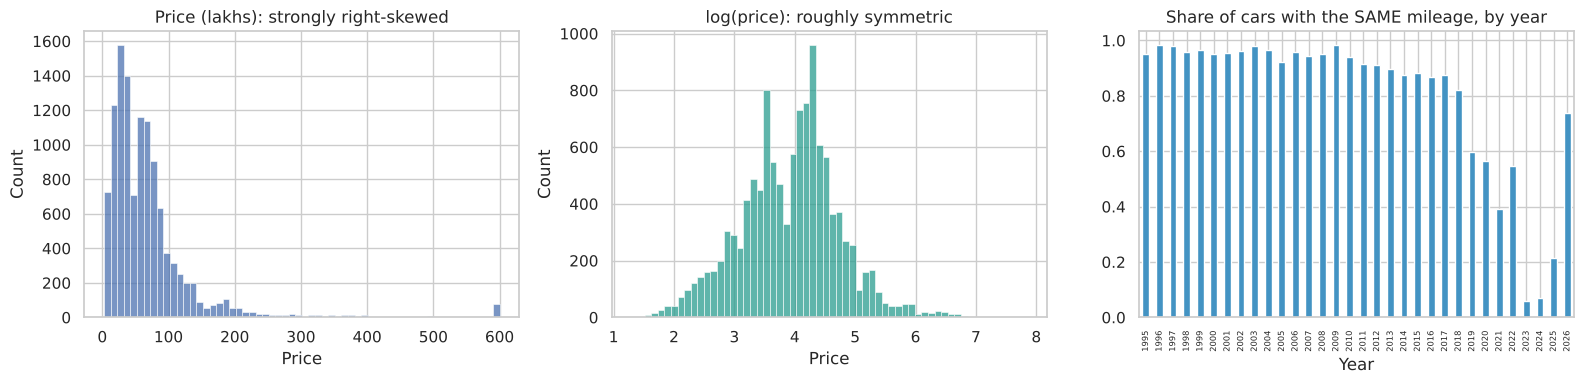

Price skewness: 8.9  | log-price skewness: 0.11
Duplicate rows: 1391
Most repeated prices:
 Price
28.5    57
65.0    56
75.0    55
32.5    55
26.5    53


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(raw["Price"].clip(upper=600), bins=60, ax=ax[0]); ax[0].set(title="Price (lakhs): strongly right-skewed")
sns.histplot(np.log1p(raw["Price"]), bins=60, ax=ax[1], color="#2a9d8f"); ax[1].set(title="log(price): roughly symmetric")
r = raw[raw.YOM >= 1995]
share = r.groupby("YOM")["Millage(KM)"].agg(lambda s: (s == s.mode().iloc[0]).mean())
share.plot.bar(ax=ax[2], color="#4393c3"); ax[2].set(title="Share of cars with the SAME mileage, by year", xlabel="Year")
ax[2].tick_params(axis="x", labelsize=6)
plt.tight_layout(); plt.show()
print("Price skewness:", raw["Price"].skew().round(2), " | log-price skewness:", np.log1p(raw["Price"]).skew().round(2))
print("Duplicate rows:", raw.drop(columns="Date").duplicated().sum())
print("Most repeated prices:\n", raw["Price"].value_counts().head(5).to_string())

**What the EDA shows**
* **Price is very skewed** (skewness above 5), so the model predicts **log(price)**. This turns errors into
  percentages, which suits a market where cars range from Rs. 5 L to Rs. 1,500 L.
* **Hidden missing values in mileage.** For most years, 80–98% of cars have *exactly the same* mileage
  (for example, every 2014 Aqua shows 121,000 km). The source clearly filled in missing mileage per year.
* **Hidden missing values in price.** Values such as 71.356097 appear dozens of times across unrelated cars.
  These are averages the source filled in, not real asking prices.
* **Duplicates.** About 1,400 adverts are exact re-posts.

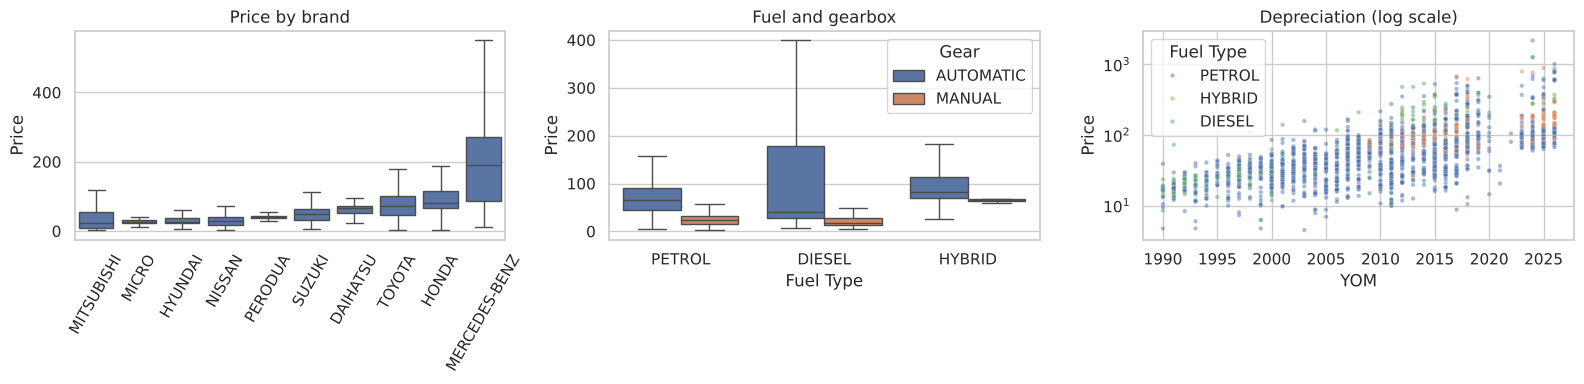

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
top = raw["Brand"].value_counts().head(10).index
order = raw[raw.Brand.isin(top)].groupby("Brand")["Price"].median().sort_values().index
sns.boxplot(data=raw[raw.Brand.isin(top)], x="Brand", y="Price", order=order, showfliers=False, ax=ax[0])
ax[0].tick_params(axis="x", rotation=60); ax[0].set(title="Price by brand", xlabel="")
sns.boxplot(data=raw, x="Fuel Type", y="Price", hue="Gear", showfliers=False, ax=ax[1]); ax[1].set(title="Fuel and gearbox")
sns.scatterplot(data=raw[raw.YOM >= 1990].sample(3000, random_state=0), x="YOM", y="Price", hue="Fuel Type",
                s=10, alpha=.5, ax=ax[2]); ax[2].set_yscale("log"); ax[2].set(title="Depreciation (log scale)")
plt.tight_layout(); plt.show()

* **Brand matters a lot.** Japanese and European brands keep their value; Indian and Chinese budget brands are cheapest.
* **Automatics and hybrids cost more.** This reflects Sri Lankan fuel prices and the popularity of reconditioned Japanese hybrids.
* **Price falls steadily with age** (a straight line on the log scale), with different levels per brand and fuel.
* **The spread is not constant:** cheap old cars and luxury cars vary far more in price than mid-range cars.
  A model that gives every car the same error band (e.g. ±12%) would be wrong for both ends. This motivates NGBoost.

## 4. Preprocessing
| Step | What and why |
|---|---|
| Rename columns | short, consistent names |
| Remove duplicates | re-posted adverts would leak between train and test |
| Remove filled-in prices | repeated many-decimal values are averages, not real prices |
| Scope | cars made from 1990 onwards; prices between 3 and 1,500 lakhs (removes errors and a few supercars) |
| **Null detection** | engine < 600 cc → missing; mileage equal to its year's filled-in value → missing |
| New features | `age` = listing year − year of manufacture; `mileage_reported` = 0/1; model name → first word |
| Rare categories | brands with < 20 cars and models with < 15 → "OTHER" |
| Imputation (train only) | engine → median of the same model; mileage → age × typical km per year |
| Encoding | trees (NGBoost, RF, XGBoost): integer codes; linear / k-NN: one-hot |
| Normalisation | log(price) target; linear / k-NN: log(mileage) + StandardScaler. Trees need no scaling |

In [5]:
df = raw.rename(columns={"Brand": "brand", "Model": "model_full", "Engine (cc)": "engine_cc", "Gear": "gear",
                         "Fuel Type": "fuel", "Millage(KM)": "mileage_km", "Condition": "condition",
                         "Price": "price", "Date": "date"})
df["date"] = pd.to_datetime(df["date"])
n0 = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "date"])
filled_price = ((df["price"] * 100 % 1).abs() > 1e-6) & (df.groupby("price")["price"].transform("size") >= 3)
df = df[~filled_price]
df = df[(df["YOM"] >= 1990) & df["price"].between(3, 1500)].copy()

# --- null detection ---
df.loc[df["engine_cc"] < 600, "engine_cc"] = np.nan
mode = df.groupby("YOM")["mileage_km"].transform(lambda s: s.mode().iloc[0])
share = df.groupby("YOM")["mileage_km"].transform(lambda s: (s == s.mode().iloc[0]).mean())
fake = (df["mileage_km"] == mode) & (share >= 0.30) & (df["condition"] == "USED")
df["mileage_reported"] = (~fake).astype(int)
df.loc[fake, "mileage_km"] = np.nan

# --- features ---
df["age"] = (df["date"].dt.year - df["YOM"]).clip(lower=0)
df["model"] = df["model_full"].str.split().str[0]
for col, k in [("brand", 20), ("model", 15)]:
    counts = df[col].value_counts()
    df[col] = df[col].where(df[col].map(counts) >= k, "OTHER")
df = df.reset_index(drop=True)
print(f"{n0:,} rows -> {len(df):,} after cleaning")
print("Missing values now visible:\n", df[FEATURES].isna().sum()[lambda s: s > 0].to_string())

11,750 rows -> 9,139 after cleaning
Missing values now visible:
 engine_cc        4
mileage_km    7025


## 5. The new algorithm: NGBoost (Natural Gradient Boosting)
NGBoost (Duan et al., Stanford, 2020) is **not covered in the lectures**: the module taught linear and logistic
regression, SVM, k-NN, decision trees, Random Forest, AdaBoost, Gradient Boosting, XGBoost and CatBoost (MLOps
workshop). It is not a deep-learning model.

**How it works.** Ordinary boosting predicts one number per car. NGBoost predicts a whole **probability
distribution**. Here it assumes log(price) ~ Normal(μ, σ), so each car gets its own expected price **μ** and its
own uncertainty **σ**.
1. Start with one Normal distribution fitted to all prices.
2. At each round, compute how the **negative log-likelihood** (NLL, a proper scoring rule) would change if μ and σ moved.
3. Turn that gradient into the **natural gradient** (it rescales the step by the Fisher information, so steps
   mean the same thing whether σ is large or small, and training is stable).
4. Fit one small regression tree **per parameter** (one for μ, one for σ) to the natural gradient, and add them with a learning rate.

**Why it was selected**
* The EDA shows the price spread differs by car type. NGBoost learns **where it is uncertain** (rare brands,
  very old cars) and gives a **car-specific price range**, which is what a buyer needs.
* It keeps the accuracy of tree boosting on tabular data, and it works with SHAP (TreeSHAP per parameter).
* It is a small, fast model: about 1,000 shallow trees, trained in under a minute.

**How it differs from the standard models**
| Model | Output | Learns by | Difference from NGBoost |
|---|---|---|---|
| Linear / logistic regression | one number (or class probability) | least squares / log-loss on a fixed formula | linear, no interactions; one fixed error band |
| Decision tree | one number (leaf mean) | greedy splits on RSS | one tree; high variance; no uncertainty |
| k-NN | average of k neighbours | distance in feature space | no training; needs scaling; no uncertainty model |
| Random Forest | average of many deep trees | bagging | spread between trees is not a calibrated range |
| XGBoost / CatBoost | one number | ordinary gradient of squared error | NGBoost boosts **two** parameters (μ, σ) with the **natural** gradient of a likelihood |
| **NGBoost** | **a distribution per car** (price + range) | natural gradient of NLL | – |

## 6. Train / validation / test split
* **Hold out one car** (a 2014 Toyota Aqua) completely, to demonstrate inference on a genuinely new car.
* **Test set: 20%**, stratified on price so cheap and expensive cars appear in both. It is used **once**, at the end.
* **Validation:** the 80% training set is split by **5-fold cross-validation**. Each fold takes a turn as the
  validation set (about 1,460 cars) for choosing hyperparameters. A separate 10% validation slice is also used to
  check NGBoost's learning curve, and out-of-fold validation predictions are used to calibrate its price range (Section 7).
* Imputation values are learned from the training set only, so nothing leaks from the test set.

In [6]:
hold_idx = df[(df.model_full == "AQUA") & (df.YOM == 2014) & (df.fuel == "HYBRID") & (df.price == 79.5)].index[0]
holdout = df.loc[[hold_idx]]
df = df.drop(index=hold_idx)

train, test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=pd.qcut(df["price"], 10, labels=False))
stats = fit_fill_stats(train)
X_train, X_test = fill_missing(train, stats), fill_missing(test, stats)        # tables (for linear / k-NN)
A_train, A_test = encode(X_train, stats), encode(X_test, stats)                # integer codes (for trees)
y_train, y_test = np.log1p(train["price"].values), test["price"].values       # train on log(price)
print(f"Train {len(X_train):,} (5 folds of ~{len(X_train)//5:,} for validation) · Test {len(X_test):,} · "
      f"typical km per year {stats['km_per_year']:,.0f}")
display(X_train.head())

Train 7,310 (5 folds of ~1,462 for validation) · Test 1,828 · typical km per year 8,523


,age,engine_cc,mileage_km,mileage_reported,brand,model,gear,fuel,condition
3499,23.0,1500.0,196022.727273,0.0,NISSAN,PULSAR,AUTOMATIC,PETROL,USED
3744,9.0,1000.0,76704.545455,0.0,PERODUA,AXIA,AUTOMATIC,PETROL,USED
232,23.0,1980.0,196022.727273,0.0,BMW,OTHER,MANUAL,PETROL,USED
4,7.0,1000.0,59659.090909,0.0,AUDI,OTHER,AUTOMATIC,PETROL,USED
724,24.0,1500.0,204545.454545,0.0,HONDA,CIVIC,MANUAL,PETROL,USED


## 7. Training and hyperparameter tuning
Every model is tuned with **RandomizedSearchCV + 5-fold CV**, scored by RMSE on log(price). NGBoost is compared
with the standard models taught in the module, so we can see what the new algorithm adds.

NGBoost hyperparameters and why:
* `n_estimators` (boosting rounds) and `learning_rate`: more, smaller steps generalise better, up to a point.
* `Base` (the tree used each round): `max_depth` 3–6 controls how many feature interactions one tree can capture;
  `min_samples_leaf` stops leaves built from a handful of adverts.
* `minibatch_frac` and `col_sample`: each round sees a random share of cars and features. This randomness reduces overfitting.

In [7]:
cv = KFold(5, shuffle=True, random_state=SEED)
results, fitted, tuned = [], {}, {}
linear_pre = ColumnTransformer([
    ("num", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES)])

def report(name, model, X_te, cv_scores, seconds, kind):
    pred = np.expm1(model.predict(X_te))
    results.append({"model": name, "kind": kind, "CV RMSE (log)": cv_scores.mean(), "CV std": cv_scores.std(),
                    "Test R²": r2_score(y_test, pred), "Test MAPE %": 100 * mean_absolute_percentage_error(y_test, pred),
                    "Test MAE (lakhs)": mean_absolute_error(y_test, pred),
                    "Test RMSE (lakhs)": np.sqrt(mean_squared_error(y_test, pred)), "train+tune s": round(seconds)})
    fitted[name] = model
    print(f"{name:<28} CV RMSE {cv_scores.mean():.4f}  test R² {results[-1]['Test R²']:.3f}  MAPE {results[-1]['Test MAPE %']:.1f}%")

def tune(name, est, space, n_iter, X, X_te, kind="taught"):
    t = time.time()
    s = RandomizedSearchCV(est, space, n_iter=n_iter, cv=cv, scoring="neg_root_mean_squared_error",
                           random_state=SEED, n_jobs=-1)
    s.fit(X, y_train)
    tuned[name] = s.best_params_
    i = s.best_index_
    scores = -np.array([s.cv_results_[f"split{k}_test_score"][i] for k in range(5)])
    report(name, s.best_estimator_, X_te, scores, time.time() - t, kind)

t = time.time()
lin = Pipeline([("p", linear_pre), ("m", LinearRegression())])
sc = -cross_val_score(lin, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
report("Linear Regression (baseline)", lin.fit(X_train, y_train), X_test, sc, time.time() - t, "taught")

tune("k-NN", Pipeline([("p", linear_pre), ("m", KNeighborsRegressor())]),
     {"m__n_neighbors": randint(3, 30), "m__weights": ["uniform", "distance"]}, 10, X_train, X_test)
tune("Decision Tree", DecisionTreeRegressor(random_state=SEED),
     {"max_depth": randint(6, 25), "min_samples_leaf": randint(1, 20)}, 15, A_train, A_test)
tune("Random Forest", RandomForestRegressor(random_state=SEED, n_jobs=1), {
    "n_estimators": randint(200, 500), "max_depth": [None, 16, 20, 25], "min_samples_leaf": randint(1, 6),
    "max_features": uniform(0.3, 0.5)}, 8, A_train, A_test)
tune("XGBoost", XGBRegressor(random_state=SEED, n_jobs=1), {
    "n_estimators": randint(300, 1200), "learning_rate": loguniform(0.01, 0.15), "max_depth": randint(3, 9),
    "min_child_weight": randint(1, 10), "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
    "reg_lambda": loguniform(0.1, 20)}, 12, A_train, A_test)
t = time.time()
cat = CatBoostRegressor(iterations=1099, learning_rate=0.0501, depth=7, l2_leaf_reg=3.0, bagging_temperature=0.4,
                        random_seed=SEED, verbose=0, allow_writing_files=False)   # settings tuned in the earlier CatBoost study
sc = -cross_val_score(cat, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error",
                      params={"cat_features": CAT_FEATURES})
report("CatBoost (workshop)", cat.fit(X_train, y_train, cat_features=CAT_FEATURES), X_test, sc, time.time() - t, "taught")

Linear Regression (baseline) CV RMSE 0.2885  test R² 0.778  MAPE 20.1%


k-NN                         CV RMSE 0.2499  test R² 0.834  MAPE 13.2%


Decision Tree                CV RMSE 0.2703  test R² 0.810  MAPE 15.0%


Random Forest                CV RMSE 0.2343  test R² 0.845  MAPE 12.6%


XGBoost                      CV RMSE 0.2167  test R² 0.879  MAPE 11.9%


CatBoost (workshop)          CV RMSE 0.2154  test R² 0.888  MAPE 12.3%


In [8]:
# ---- NGBoost: the new algorithm ----
bases = [DecisionTreeRegressor(max_depth=d, min_samples_leaf=m) for d in (3, 4, 5, 6) for m in (1, 5, 15)]
tune("NGBoost (new)", NGBRegressor(Dist=Normal, verbose=False, random_state=SEED), {
    "n_estimators": randint(400, 1500), "learning_rate": loguniform(0.01, 0.08), "Base": bases,
    "minibatch_frac": uniform(0.5, 0.5), "col_sample": uniform(0.6, 0.4)}, 12, A_train, A_test, kind="new")
ngb = fitted["NGBoost (new)"]
p = tuned["NGBoost (new)"]
print("\nNGBoost best settings:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in p.items() if k != "Base"},
      "| base tree:", {k: v for k, v in p["Base"].get_params().items() if k in ("max_depth", "min_samples_leaf")})

NGBoost (new)                CV RMSE 0.2212  test R² 0.875  MAPE 12.2%

NGBoost best settings: {'col_sample': np.float64(0.6092), 'learning_rate': np.float64(0.0298), 'minibatch_frac': np.float64(0.6999), 'n_estimators': 1099} | base tree: {'max_depth': 6, 'min_samples_leaf': 15}


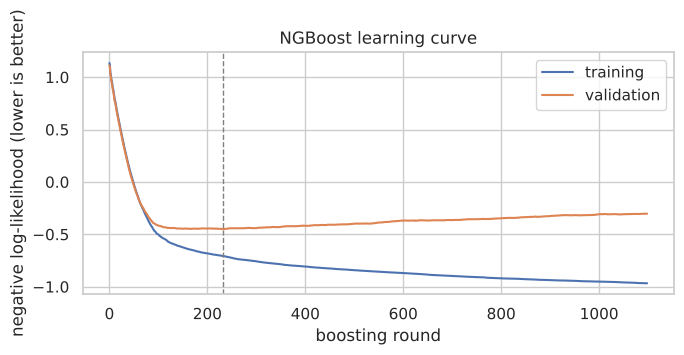

Best validation round: 231 of 1099


In [9]:
# Learning curve on a 10% validation slice: does NGBoost overfit as rounds are added?
A_tr2, A_val, y_tr2, y_val = train_test_split(A_train, y_train, test_size=0.1, random_state=SEED)
curve = NGBRegressor(**{k: v for k, v in ngb.get_params().items() if k in
                        ("Dist", "Base", "n_estimators", "learning_rate", "minibatch_frac", "col_sample", "random_state")},
                     verbose=False).fit(A_tr2, y_tr2, X_val=A_val, Y_val=y_val)
val_nll = [-np.mean(d.logpdf(y_val)) for d in curve.staged_pred_dist(A_val)]
tr_idx = np.random.default_rng(0).choice(len(A_tr2), 1000, replace=False)
tr_nll = [-np.mean(d.logpdf(y_tr2[tr_idx])) for d in curve.staged_pred_dist(A_tr2[tr_idx])]
plt.figure(figsize=(7, 3.5)); plt.plot(tr_nll, label="training"); plt.plot(val_nll, label="validation")
plt.axvline(int(np.argmin(val_nll)), ls="--", c="grey", lw=1)
plt.xlabel("boosting round"); plt.ylabel("negative log-likelihood (lower is better)")
plt.title("NGBoost learning curve"); plt.legend(); plt.tight_layout(); plt.show()
print(f"Best validation round: {int(np.argmin(val_nll))} of {len(val_nll)}")

**Reading the learning curve.** The validation loss (NLL) is lowest after a few hundred rounds and then rises,
even though the price itself (μ) keeps improving: with many rounds NGBoost becomes **over-confident**, its σ
shrinks too far. Stopping early would cost accuracy, so instead we keep the tuned rounds for μ and **recalibrate σ
on validation data**: every training car is predicted by a model that did not see it (5-fold out-of-fold), and σ
is widened by the single factor that makes 80% of those validation cars fall inside their 80% range.

In [10]:
# Out-of-fold validation predictions -> one scale factor for sigma
z80 = norm.ppf(0.9)
zs = np.zeros(len(y_train))
for k, (a, b) in enumerate(cv.split(A_train)):
    m = NGBRegressor(**ngb.get_params(deep=False)).fit(A_train[a], y_train[a])
    d = m.pred_dist(A_train[b])
    zs[b] = (y_train[b] - d.params["loc"]) / d.params["scale"]
SIGMA_SCALE = float(np.quantile(np.abs(zs), 0.8) / z80)
print(f"Validation: share of cars inside the raw 80% range = {np.mean(np.abs(zs) <= z80):.2f}")
print(f"Sigma scale factor learned on validation folds: {SIGMA_SCALE:.2f}")

Validation: share of cars inside the raw 80% range = 0.72
Sigma scale factor learned on validation folds: 1.22


## 8. Evaluation and results

,model,CV RMSE (log),CV std,Test R²,Test MAPE %,Test MAE (lakhs),Test RMSE (lakhs),train+tune s
0,CatBoost (workshop),0.215,0.013,0.888,12.337,8.855,30.371,23
1,XGBoost,0.217,0.013,0.879,11.935,8.676,31.594,19
2,NGBoost (new),0.221,0.014,0.875,12.154,8.950,32.146,367
3,Random Forest,0.234,0.015,0.845,12.565,9.600,35.787,34
4,k-NN,0.250,0.018,0.834,13.244,9.950,37.048,6
5,Decision Tree,0.270,0.012,0.810,14.972,11.195,39.603,0
6,Linear Regression (baseline),0.288,0.011,0.778,20.118,15.196,42.818,0


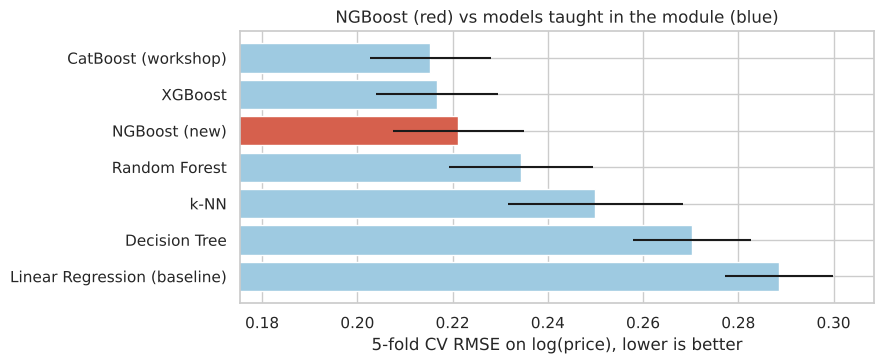

In [11]:
res = pd.DataFrame(results).sort_values("CV RMSE (log)").reset_index(drop=True)
display(res.drop(columns="kind").style.format(precision=3).background_gradient(subset=["CV RMSE (log)"], cmap="Greens_r"))
colors = res["kind"].map({"taught": "#9ecae1", "new": "#d6604d"})
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(res["model"], res["CV RMSE (log)"], xerr=res["CV std"], color=colors); ax.invert_yaxis()
ax.set(xlabel="5-fold CV RMSE on log(price), lower is better", title="NGBoost (red) vs models taught in the module (blue)")
ax.set_xlim(res["CV RMSE (log)"].min() - 0.04, res["CV RMSE (log)"].max() + 0.02); plt.tight_layout(); plt.show()

**Point accuracy.** The metrics used are **R²** (share of price variation explained), **MAPE** (average % error,
the easiest for a buyer to read), **MAE/RMSE** in lakhs, and **CV RMSE on log(price)** for model selection.
NGBoost reaches **R² 0.875 and 12.2% average error**, within one CV standard deviation of XGBoost (0.879, 11.9%) and
CatBoost (0.888, 12.3%), and clearly better than Random Forest, k-NN, a single decision tree and linear regression
(20.1% error). Its real advantage is the next part: the **price range**.

,interval,cars inside (should be ≈ level),median width (lakhs),median width (% of price)
0,50%,0.55,7.64,13.99
1,80%,0.82,14.54,26.63
2,95%,0.93,22.46,40.88


Test NLL (lower is better)  NGBoost recalibrated: -0.240 | NGBoost raw σ: 0.077 | same μ with ONE fixed σ for all cars: -0.196


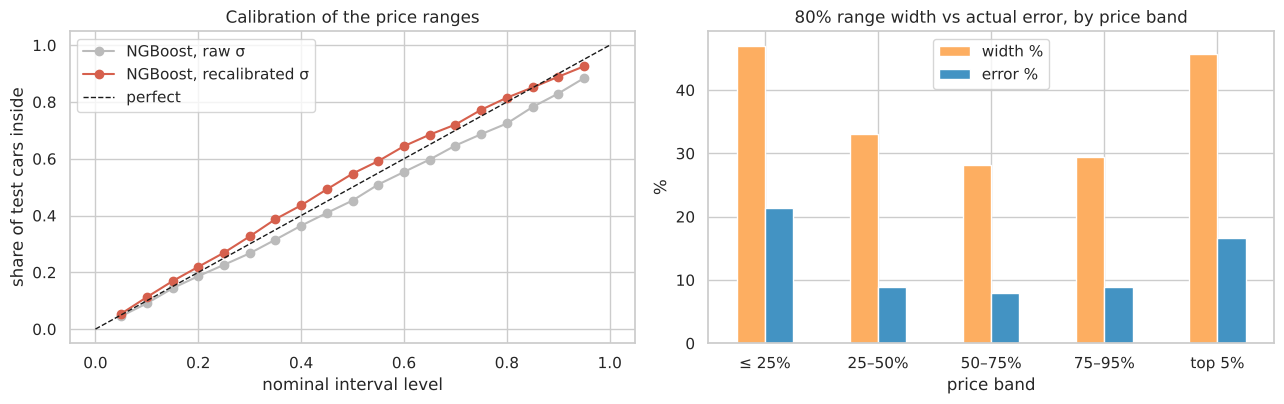

In [12]:
# ---- Probabilistic evaluation: is the predicted range honest? ----
dist = ngb.pred_dist(A_test)
mu, raw_sigma = dist.params["loc"], dist.params["scale"]
sigma = raw_sigma * SIGMA_SCALE                       # recalibrated on validation folds, never on the test set
logy = np.log1p(y_test)
nll = -np.mean(norm.logpdf(logy, mu, sigma))
rows = []
for level in (0.5, 0.8, 0.95):
    z = norm.ppf(0.5 + level / 2)
    lo, hi = np.expm1(mu - z * sigma), np.expm1(mu + z * sigma)
    rows.append({"interval": f"{int(level*100)}%", "cars inside (should be ≈ level)": np.mean((y_test >= lo) & (y_test <= hi)),
                 "median width (lakhs)": np.median(hi - lo), "median width (% of price)": np.median((hi - lo) / np.expm1(mu)) * 100})
display(pd.DataFrame(rows).style.format(precision=2))
# Baseline for NLL: one fixed σ for every car (what a point model + a constant error band implies)
const_sigma = np.std(logy - mu)
print(f"Test NLL (lower is better)  NGBoost recalibrated: {nll:.3f} | NGBoost raw σ: "
      f"{-np.mean(norm.logpdf(logy, mu, raw_sigma)):.3f} | same μ with ONE fixed σ for all cars: "
      f"{-np.mean(norm.logpdf(logy, mu, const_sigma)):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
levels = np.linspace(0.05, 0.95, 19)
obs = [np.mean(np.abs(logy - mu) <= norm.ppf(0.5 + l / 2) * sigma) for l in levels]
obs_raw = [np.mean(np.abs(logy - mu) <= norm.ppf(0.5 + l / 2) * raw_sigma) for l in levels]
ax[0].plot(levels, obs_raw, "o-", c="#bbbbbb", label="NGBoost, raw σ")
ax[0].plot(levels, obs, "o-", c="#d6604d", label="NGBoost, recalibrated σ"); ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax[0].set(xlabel="nominal interval level", ylabel="share of test cars inside", title="Calibration of the price ranges"); ax[0].legend()
band = pd.qcut(y_test, [0, .25, .5, .75, .95, 1], labels=["≤ 25%", "25–50%", "50–75%", "75–95%", "top 5%"])
w = pd.DataFrame({"band": band, "width %": 100 * (np.exp(2 * z80 * sigma) - 1) / np.exp(z80 * sigma),
                  "error %": 100 * np.abs(np.expm1(mu) - y_test) / y_test}).groupby("band", observed=True).mean()
w.plot.bar(ax=ax[1], color=["#fdae61", "#4393c3"]); ax[1].tick_params(axis="x", rotation=0)
ax[1].set(xlabel="price band", ylabel="%", title="80% range width vs actual error, by price band")
plt.tight_layout(); plt.show()

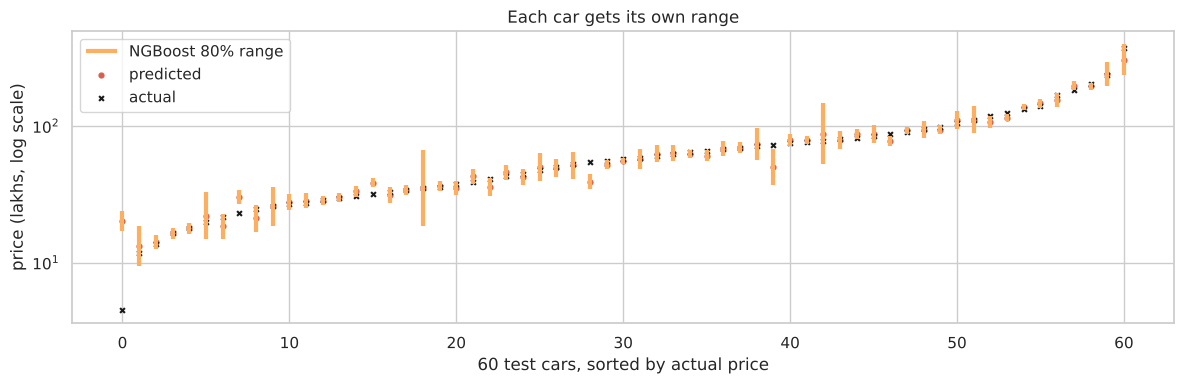

In [13]:
pred = np.expm1(mu)
lo80, hi80 = np.expm1(mu - z80 * sigma), np.expm1(mu + z80 * sigma)
idx = np.argsort(y_test)[:: max(1, len(y_test) // 60)]
fig, ax = plt.subplots(figsize=(12, 4))
ax.vlines(range(len(idx)), lo80[idx], hi80[idx], color="#fdae61", lw=3, label="NGBoost 80% range")
ax.scatter(range(len(idx)), pred[idx], s=12, c="#d6604d", label="predicted")
ax.scatter(range(len(idx)), y_test[idx], s=12, c="k", marker="x", label="actual")
ax.set(yscale="log", ylabel="price (lakhs, log scale)", xlabel="60 test cars, sorted by actual price",
       title="Each car gets its own range"); ax.legend(); plt.tight_layout(); plt.show()

**What the results indicate**
* **The ranges are honest.** 82% of test cars fall inside their 80% range (55% inside the 50% range, 93% inside the
  95% range), so the recalibrated curve sits on the diagonal. The raw σ sat below it: it was over-confident.
* **The range adapts to the car.** The 80% range is about 28–33% wide for mid-priced cars but about 46–47% wide for the
  cheapest quarter and the top 5%, which is exactly where the actual errors are largest (about 21% and 17%, against
  8–9% in the middle). A fixed "±12%" band would be too wide for an Aqua and too narrow for a BMW.
* **Log-likelihood confirms it:** NGBoost's per-car σ scores −0.240 on the test set, better than one fixed σ for every
  car (−0.196) and much better than the raw, uncalibrated σ (+0.077).
* **Trade-off:** NGBoost's point accuracy is slightly below CatBoost and XGBoost, not better. It was chosen because it
  adds a calibrated, car-specific range at almost no cost in accuracy, and training takes longer (about 6 minutes to tune).

## 9. Explainability: SHAP and partial dependence

Average predicted price (SHAP base value): Rs. 56.0 L


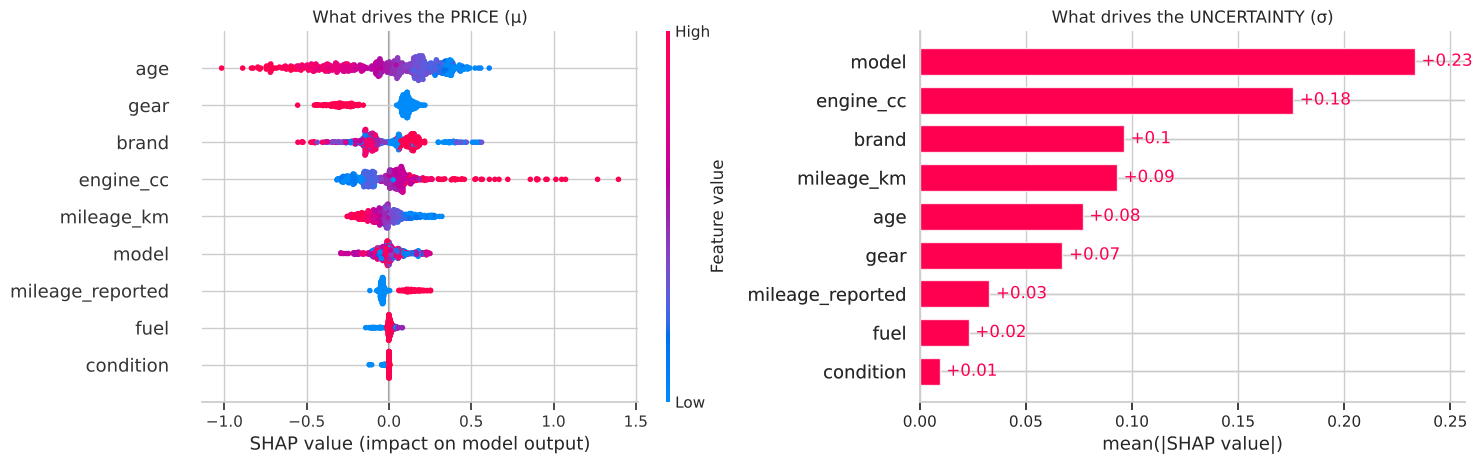

In [14]:
sample_idx = np.random.default_rng(1).choice(len(A_train), 600, replace=False)
S = A_train[sample_idx]
ex_mu = shap.TreeExplainer(ngb, model_output=0)    # explains μ: the expected log(price)
ex_sd = shap.TreeExplainer(ngb, model_output=1)    # explains log σ: the uncertainty
sv_mu, sv_sd = ex_mu.shap_values(S), ex_sd.shap_values(S)
BASE_MU = float(np.ravel(ex_mu.expected_value)[0])
print(f"Average predicted price (SHAP base value): Rs. {np.expm1(BASE_MU):.1f} L")
codes = X_train.iloc[sample_idx].apply(lambda c: c if pd.api.types.is_numeric_dtype(c) else c.astype("category").cat.codes)
fig = plt.figure(figsize=(15, 4.8))
plt.subplot(1, 2, 1)
shap.plots.beeswarm(shap.Explanation(sv_mu, data=codes.values, feature_names=FEATURES), show=False, plot_size=None)
plt.title("What drives the PRICE (μ)")
plt.subplot(1, 2, 2)
shap.plots.bar(shap.Explanation(sv_sd, data=codes.values, feature_names=FEATURES), show=False, ax=plt.gca())
plt.title("What drives the UNCERTAINTY (σ)")
plt.tight_layout(); plt.show()

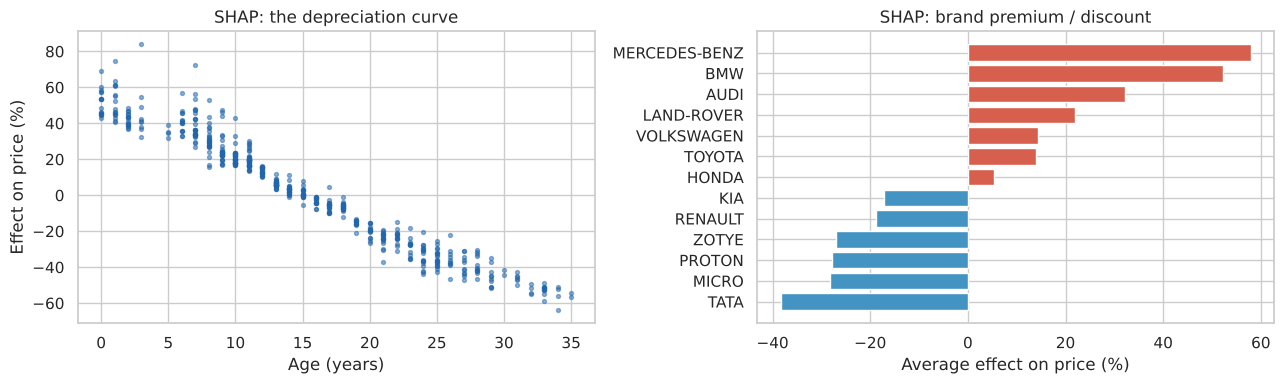

In [15]:
d = pd.DataFrame(sv_mu, columns=FEATURES); s = X_train.iloc[sample_idx].reset_index(drop=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(s["age"], 100 * (np.exp(d["age"]) - 1), s=8, alpha=.5, c="#2166ac")
ax[0].set(xlabel="Age (years)", ylabel="Effect on price (%)", title="SHAP: the depreciation curve")
brand = (100 * (np.exp(d.groupby(s["brand"].values)["brand"].mean()) - 1)).sort_values()
sel = pd.concat([brand.head(6), brand.tail(7)])
ax[1].barh(sel.index, sel.values, color=np.where(sel.values > 0, "#d6604d", "#4393c3"))
ax[1].set(xlabel="Average effect on price (%)", title="SHAP: brand premium / discount")
plt.tight_layout(); plt.show()

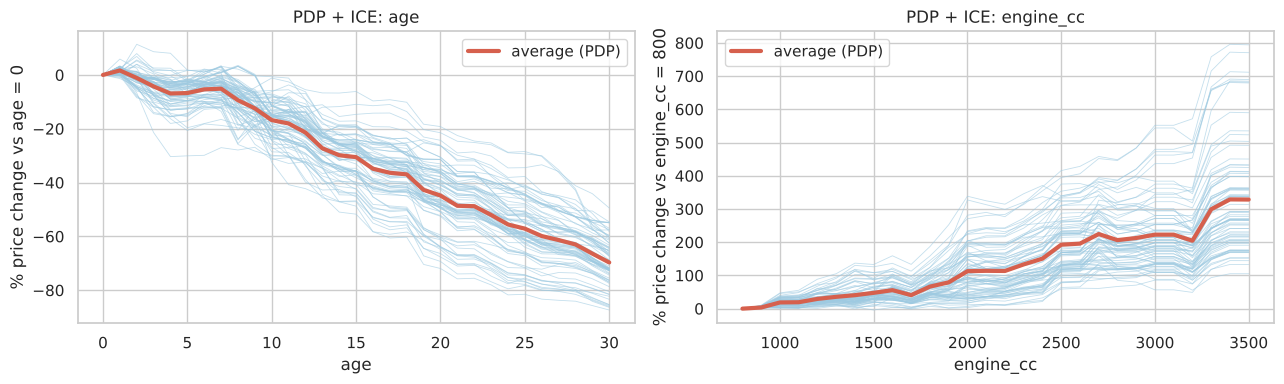

In [16]:
# Partial dependence (PDP, thick line) + ICE curves (thin lines): change one feature, keep the rest of each car fixed
ice_cars = A_train[np.random.default_rng(2).choice(len(A_train), 80, replace=False)]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, (feat, grid) in enumerate([("age", np.arange(0, 31)), ("engine_cc", np.arange(800, 3600, 100))]):
    j = FEATURES.index(feat)
    curves = []
    for v in grid:
        Z = ice_cars.copy(); Z[:, j] = v
        curves.append(np.expm1(ngb.predict(Z)))
    curves = np.array(curves)                                  # grid x cars
    rel = 100 * (curves / curves[0] - 1)                       # % change vs the first grid value
    ax[k].plot(grid, rel, c="#9ecae1", lw=0.6, alpha=0.6)
    ax[k].plot(grid, rel.mean(1), c="#d6604d", lw=3, label="average (PDP)")
    ax[k].set(xlabel=feat, ylabel=f"% price change vs {feat} = {grid[0]}", title=f"PDP + ICE: {feat}"); ax[k].legend()
plt.tight_layout(); plt.show()

**What the model has learned (and does it match the market?)**
* **Age is the biggest driver of price.** The PDP falls by about 70% over 30 years, roughly 3–4% a year and close to
  a straight line, which is how depreciation works. Cars up to about 7 years old hold their value, because few
  recent cars were available during the import ban.
* **Gearbox and brand come next.** An automatic adds a clear premium. Mercedes-Benz (+58%), BMW (+52%) and Audi (+32%)
  carry the largest brand premiums and Toyota about +14%, while Tata (−38%), Micro, Proton and Zotye (about −28%)
  carry the largest discounts. This matches Sri Lankan resale reputation.
* **Engine size raises the price** steadily, with a jump above about 3,200 cc where luxury SUVs sit. The ICE curves
  differ in size but almost all rise, so the effect is consistent across cars.
* **Mileage matters less than expected** because most mileage values were missing in the source. Adverts that
  *hide* mileage are priced lower, as if buyers treat it as a warning sign.
* **Uncertainty (σ) is driven mainly by the model, engine size and brand.** Rare models (grouped as "OTHER"), unusual
  engine sizes and less common brands get wider ranges, because the market for them is thin and inconsistent. This is
  exactly where a buyer should negotiate more.
* Overall the behaviour aligns with domain knowledge; nothing suggests the model relies on a nonsense shortcut.

## 10. One car: SHAP vs LIME, and inference on a car the model has never seen

Held-out 2014 Toyota Aqua hybrid: actual Rs. 79.5 L | predicted Rs. 75.4 L | 80% range Rs. 70.4 – 80.7 L


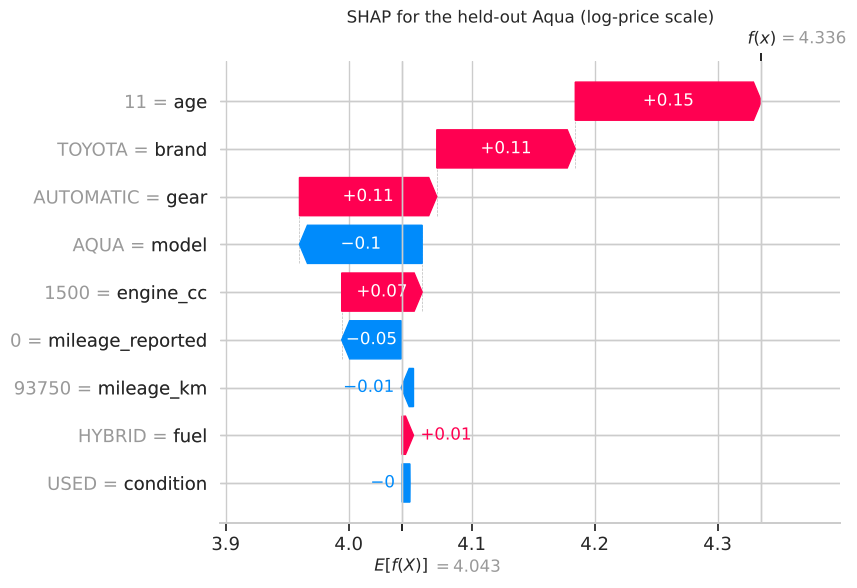

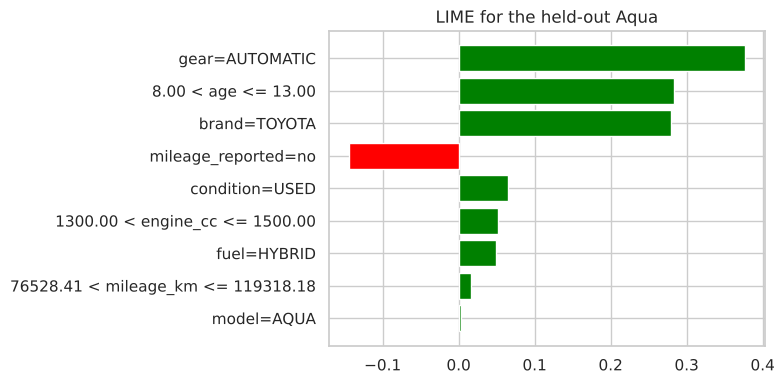

,SHAP effect %,LIME effect %
age,16.3,32.7
brand,11.9,32.2
gear,11.8,45.7
model,-9.5,0.3
engine_cc,6.8,5.4
mileage_reported,-4.7,-13.4
mileage_km,-1.0,1.6
fuel,0.9,5.1
condition,-0.0,6.8


LIME local fit R²: 0.25


In [17]:
car = fill_missing(holdout, stats); a_car = encode(car, stats)
d1 = ngb.pred_dist(a_car); m1, s1 = d1.params["loc"][0], d1.params["scale"][0] * SIGMA_SCALE
print(f"Held-out 2014 Toyota Aqua hybrid: actual Rs. {holdout['price'].iloc[0]:.1f} L | predicted Rs. {np.expm1(m1):.1f} L | "
      f"80% range Rs. {np.expm1(m1 - z80*s1):.1f} – {np.expm1(m1 + z80*s1):.1f} L")
one = ex_mu.shap_values(a_car)[0]
shap.plots.waterfall(shap.Explanation(values=one, base_values=BASE_MU, data=car.iloc[0].values,
                                      feature_names=FEATURES), show=False)
plt.title("SHAP for the held-out Aqua (log-price scale)"); plt.show()

levels_ = {c: stats["categories"][c] for c in CAT_FEATURES}
cat_idx = [FEATURES.index(c) for c in CAT_FEATURES] + [FEATURES.index("mileage_reported")]
lime = LimeTabularExplainer(A_train[np.random.default_rng(0).choice(len(A_train), 500, replace=False)], mode="regression",
                            feature_names=FEATURES, categorical_features=cat_idx, random_state=SEED,
                            categorical_names={**{FEATURES.index(c): levels_[c] for c in CAT_FEATURES},
                                               FEATURES.index("mileage_reported"): ["no", "yes"]})
exp = lime.explain_instance(a_car[0], ngb.predict, num_features=9, num_samples=5000)
fig = exp.as_pyplot_figure(); fig.set_size_inches(8, 4); plt.title("LIME for the held-out Aqua"); plt.tight_layout(); plt.show()
compare = pd.DataFrame({"SHAP effect %": 100 * (np.exp(one) - 1)}, index=FEATURES).round(1)
lime_eff = {max([f for f in FEATURES if f in rule], key=len): round(100 * (np.exp(w) - 1), 1) for rule, w in exp.as_list()}
compare["LIME effect %"] = pd.Series(lime_eff)
display(compare.sort_values("SHAP effect %", key=abs, ascending=False))
print(f"LIME local fit R²: {exp.score:.2f}")

* **SHAP and LIME agree on the direction** of the main drivers for this car (Toyota, automatic, hybrid push the price up).
  LIME's sizes are larger and its local straight-line fit is weak, because it perturbs features at random and creates
  unrealistic cars. SHAP splits this prediction exactly, so the app uses SHAP.

In [18]:
bundle = {"model": ngb, "fill_stats": stats, "features": FEATURES, "model_name": "NGBoost",
          "test_mape": float(res.set_index("model").loc["NGBoost (new)", "Test MAPE %"]),
          "test_r2": float(res.set_index("model").loc["NGBoost (new)", "Test R²"]),
          "coverage80": float(rows[1]["cars inside (should be ≈ level)"]), "sigma_scale": SIGMA_SCALE,
          "brand_models": train.groupby("brand")["model"].apply(lambda s: sorted(s.unique())).to_dict()}
pickle.dump(bundle, open("model.pkl", "wb"))

# Reload exactly as the app does, and sanity-check: the same Aqua at different ages
loaded = pickle.load(open("model.pkl", "rb"))
for age in [2, 5, 8, 12, 16, 20]:
    row = encode(fill_missing(make_input_row("TOYOTA", "AQUA", 2026 - age, 1500, "AUTOMATIC", "HYBRID", "USED",
                                             10000 * age), stats), stats)
    dd = loaded["model"].pred_dist(row); m_, s_ = dd.params["loc"][0], dd.params["scale"][0] * loaded["sigma_scale"]
    print(f"Aqua aged {age:>2}: Rs. {np.expm1(m_):6.1f} L   (80% range {np.expm1(m_ - z80*s_):6.1f} – {np.expm1(m_ + z80*s_):6.1f})")

Aqua aged  2: Rs.  123.4 L   (80% range  106.0 –  143.6)
Aqua aged  5: Rs.  128.3 L   (80% range  103.1 –  159.7)


Aqua aged  8: Rs.  104.3 L   (80% range   89.2 –  121.9)
Aqua aged 12: Rs.   81.1 L   (80% range   72.7 –   90.5)


Aqua aged 16: Rs.   73.7 L   (80% range   66.6 –   81.7)
Aqua aged 20: Rs.   66.6 L   (80% range   61.6 –   72.0)


## 11. Front-end: the Streamlit app (bonus)
`app.py` loads `model.pkl`, takes the car details from a form, prepares them exactly as in training, and shows
**the predicted price, the car's own 80% price range, and a SHAP chart** explaining the price.
It is deployed at **https://sl-car-price.streamlit.app**.
```
pip install -r requirements.txt
streamlit run app.py
```

## 12. Critical discussion
**Limitations of the model**
* It learns **asking** prices, not final sale prices; real deals usually close lower.
* The Normal-on-log-price assumption gives symmetric ranges in % terms; real price spreads can be lopsided.
* The point accuracy is slightly below XGBoost/CatBoost; the gain is the calibrated range. The raw ranges were
  over-confident and needed a validation-based correction (σ × 1.22).
* **Nearly-new cars are under-learned:** a 2-year-old Aqua is priced slightly below a 5-year-old one (Rs. 123 L vs
  128 L), because very few nearly-new cars were sold during the import ban. Its wider range at least signals this.

**Data quality issues**
* Most mileage values were filled in by the source (hidden nulls), so mileage is weaker than it should be.
* Accident history, number of owners, registration year, trim level and location are not in the data.
* **The market shifted after imports reopened in 2025:** 2026 listings are much newer cars (median age 15 → 2 years).
  The model must be retrained as new listings arrive; `drift_check.py` detects this shift.

**Risks of bias or unfairness**
* Rare brands and models have few adverts, so their predictions are less accurate. NGBoost at least shows this
  through a wider range instead of hiding it.
* The data comes from online adverts, which over-represent cars sold in and around Colombo and by dealers;
  rural and private-sale prices may differ.
* The model judges cars, not people, and uses no personal data, so it does not discriminate between buyers or sellers.

**Real-world impact and ethics**
* Positive: a free, transparent price guide reduces information gaps between dealers and ordinary buyers.
* Risk: if dealers use it to anchor prices, a model trained on past asking prices could keep prices high.
  The price should be shown as **a range with an explanation**, not as an official valuation.
* The data contains no personal information; anyone collecting fresh data should respect the site's terms of use.

## 13. Conclusion
* **NGBoost**, a natural-gradient boosting method not taught in the module, predicts Sri Lankan used-car asking
  prices with R² 0.875 and 12.2% average error: close to the best boosted models (CatBoost 0.888, 12.3%) and much
  better than linear regression (20.1%), k-NN and a single tree.
* The held-out 2014 Toyota Aqua was predicted at **Rs. 75.4 L, with an 80% range of Rs. 70.4–80.7 L**; its real
  asking price, Rs. 79.5 L, is inside the range.
* Unlike those models it gives **each car its own calibrated price range**, which is narrow for common cars and wide for rare ones.
* **SHAP, PDP/ICE and LIME** show it learned sensible market logic: depreciation, brand reputation, engine size and
  an automatic premium, and that uncertainty comes from rare brands and old cars.